# Final Project: Socioeconomic Factors in Diabetes Risk Prediction
**Geisel School of Medicine at Dartmouth**

**Health Data Science HSE 751**

**`Samira Rahman`**

This notebook implements a complete, reproducible analysis pipeline for predicting diabetes/prediabetes risk from demographic, socioeconomic, behavioral, and health-status indicators.

**Using your own dataset:** This notebook is built to run on any binary-classification dataset that meets the project's requirements (a binary target column, at least 300 rows, at least 10 predictor columns). Upload a CSV when prompted in Part 1 below, and set `TARGET_COL` to your target column's name. If you don't upload a file, the notebook falls back to the CDC Diabetes Health Indicators dataset used for this project.


## Part 1: Data Input and Validation

### 1.1 Formalizing the machine learning problem

Before loading or exploring any data, it's worth stating the prediction problem in formal notation, the same structure this applies to throughout the rest of the notebook.

$$\mathcal{D} = \{(x_i, y_i)\}_{i=1}^{n}, \qquad x_i \in \mathbb{R}^{p}, \qquad y_i \in \{0, 1\}$$

- $\mathcal{D}$ denotes the complete dataset.
- $n$ is the total number of observations (rows) in the dataset. For this project, $n = 253{,}680$.
- $i$ represents the index of an individual observation, where $i = 1, 2, \dots, n$.
- $x_i$ is the feature vector (predictor variables) corresponding to the $i^{th}$ observation.
- $p$ is the total number of predictor (feature) variables. For this project, $p = 21$.
- $\mathbb{R}^p$ denotes the $p$-dimensional real-valued feature space.
- $y_i$ is the target (response) variable associated with observation $i$.
- $\{0, 1\}$ indicates that this is a **binary classification** problem, where:
  - $0$ represents no diabetes
  - $1$ represents diabetes/prediabetes

For the CDC Diabetes Health Indicators dataset used in this notebook,

$$
x_i =
\begin{bmatrix}
\text{HighBP} \\
\text{HighChol} \\
\text{CholCheck} \\
\text{BMI} \\
\text{Smoker} \\
\text{Stroke} \\
\text{HeartDiseaseorAttack} \\
\text{PhysActivity} \\
\text{Fruits} \\
\text{Veggies} \\
\text{HvyAlcoholConsump} \\
\text{AnyHealthcare} \\
\text{NoDocbcCost} \\
\text{GenHlth} \\
\text{MentHlth} \\
\text{PhysHlth} \\
\text{DiffWalk} \\
\text{Sex} \\
\text{Age} \\
\text{Education} \\
\text{Income}
\end{bmatrix},
\qquad
y_i = \text{Diabetes_binary}.
$$

Thus, each observation is represented by a vector of predictor variables, and the machine learning algorithm learns an estimated prediction function

$$\hat{f} : \mathbb{R}^{p} \to \{0, 1\},$$

where

- $\hat{f}$ (pronounced "f-hat") denotes the **estimated prediction function** learned from the training data.
- The "hat" indicates that the function is an **estimate** of the unknown true relationship between the predictor variables and the target variable.

The function $\hat{f}(\cdot)$ maps an observation's predictor variables to a predicted class label.

The objective of supervised learning is to estimate the function $\hat{f}(\cdot)$ so that it accurately predicts the target variable for observations that were **not** used during model training.

**Candidate evaluation metric:** Section 2.4 shows that about 86% of respondents fall in the "no diabetes" class and only about 14% fall in the "diabetes/prediabetes" class. That imbalance matters for metric choice: a model could predict "no diabetes" for every single respondent and still be right 86% of the time, while being completely useless at actually identifying at-risk people. So accuracy alone isn't a good measure of whether the model is doing its job here.

Instead, this project uses **recall (sensitivity)** as the primary metric. Recall measures how many of the actual diabetes/prediabetes cases the model successfully catches. In a screening-type context like this, missing someone who actually has the condition (a false negative) is generally a more costly mistake than flagging someone who turns out not to have it (a false positive), since a false positive just means an extra follow-up check, while a false negative means a real case goes unnoticed. As a secondary metric, AUC-ROC is also tracked, which measures how well the model separates the two classes overall, independent of any single decision threshold, useful for comparing different models before deciding where to set that threshold.

### 1.2 Data Selection
**Dataset name:** CDC Diabetes Health Indicators

**Source:** UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators

This dataset is from the CDC's 2015 Behavioral Risk Factor Surveillance System (BRFSS) survey and contains 253,680 individual responses with 21 predictor variables. The binary outcome variable is diabetes/prediabetes vs. no diabetes.

What drew me to this dataset is the socioeconomic angle. Income, education, and healthcare access show up here as direct, measured variables sitting right alongside clinical and behavioral indicators, which makes it a good fit for asking how socioeconomic position relates to diabetes risk at the individual level. Diabetes prevalence tracks closely with income and access to care, and with a large scale responses, this dataset lets me actually test that relationship instead of just inferring it from aggregate numbers.

### 1.3 Dataset Import

**Instructions on Loading a Dataset**

Before the data can be explored or any model can be built, it first has to be loaded into memory and verified as imported correctly. This notebook supports two ways to do that:

- **Upload your own CSV** when prompted by the cell below, provided it meets the project's scope and requirements (a binary target column, at least 300 rows, at least 10 predictor columns).
- **Use the project's default dataset** by clicking Cancel in the upload dialog instead. The notebook then falls back to fetching the CDC Diabetes Health Indicators dataset directly from the UCI repository.

For the default dataset specifically:

- Each row represents one BRFSS survey respondent (one observation).
- Each column represents either a predictor (feature) variable or the target variable.
- The target variable is **`Diabetes_binary`**, where:
  - `0` indicates the respondent does **not** have diabetes.
  - `1` indicates the respondent has diabetes or prediabetes.

A custom upload will have its own target column name, set via `TARGET_COL` at the top of the cell below, and its own variable meanings, which is why the automated profiling and validation sections exist: they check the dataset's actual structure programmatically rather than assuming it matches the default.

Before performing any statistical analysis or developing predictive models, it's important to understand the basic structure of whichever dataset was loaded. Specifically, Part 1 verifies:

- The number of observations (rows) and variables (columns).
- The names and meanings of the variables.
- Whether the target variable is binary.
- Whether the dataset was imported successfully.
- Whether there are any obvious issues that require further investigation before continuing the analysis.

**Inspect the Dataset**

Inspecting the first few observations lets us verify that the dataset loaded correctly, confirm the variables appear as expected, and catch any obvious issues before going further. The `head()` call at the end of the cell below displays the first five observations.

In [1]:
# =============================================================================
# DATA INPUT (UPLOAD WITH FALLBACK TO DEFAULT DATASET)
# =============================================================================
# Allows a user to upload their own CSV. If nothing is uploaded (or the
# upload widget isn't available outside Colab), falls back to fetching
# this project's default dataset (CDC Diabetes Health Indicators, UCI id=891).
# =============================================================================
# Install the UCI ML Repo package (needed for the fallback fetch below;
# not needed if you upload your own CSV)
!pip install ucimlrepo
import pandas as pd

TARGET_COL = "Diabetes_binary"  # change this if you upload a dataset with a different target column name

def load_dataset(default_fetch_id=891, default_target_col="Diabetes_binary"):
    """Try to load a user-uploaded CSV first. If nothing is uploaded
    (or the upload widget isn't available, e.g. running outside Colab),
    fall back to the project's default dataset."""
    try:
        # Step 1: offer the upload widget (Colab-only)
        from google.colab import files
        print("Upload a CSV file, or click Cancel to use the default dataset.")
        uploaded = files.upload()
        if uploaded:
            # Step 2a: a file was uploaded (read it directly)
            filename = list(uploaded.keys())[0]
            df = pd.read_csv(filename)
            print(f"Loaded uploaded file '{filename}': {df.shape[0]:,} rows, {df.shape[1]} columns.")
            return df, None  # no UCI metadata for a custom upload
    except Exception as e:
        # Step 2b: no file uploaded, or upload unavailable (e.g. not running in Colab)
        print(f"No file uploaded or upload unavailable ({e}). Falling back to default dataset.")

    # Step 3: fallback (fetch the project's default dataset from UCI)
    from ucimlrepo import fetch_ucirepo
    fetched = fetch_ucirepo(id=default_fetch_id)
    df = pd.concat([fetched.data.features, fetched.data.targets], axis=1)  # combine features + target into one df
    print(f"Loaded default dataset: {df.shape[0]:,} rows, {df.shape[1]} columns.")
    return df, fetched


df, uci_metadata = load_dataset(default_fetch_id=891, default_target_col=TARGET_COL)
df.head()


Upload a CSV file, or click Cancel to use the default dataset.


Loaded default dataset: 253,680 rows, 22 columns.


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


### 1.4 Automated data profiling

A quick structural summary of whatever dataset was loaded.

**Determine the Dimensions of the Dataset**

Before analyzing individual variables, it is important to understand the overall size of the dataset.

The dimensions of a dataset describe:

- The number of observations (rows).
- The number of variables (columns).

Understanding the dimensions of the dataset helps us answer questions such as:

- How many observations are available for model development?
- How many predictor variables are available?
- Is the dataset relatively small, moderate, or large?
- Does the number of observations appear sufficient for building a machine learning model?

The `shape` attribute returns a tuple containing the number of rows followed by the number of columns.

For a DataFrame with **n** observations and **p** variables,

$$
\text{shape}=(n,p)
$$

where

- \(n\) represents the number of observations (rows).
- \(p\) represents the number of variables (columns).

`profile_dataset()` below reports this directly, along with column types, missing values, cardinality, and the full per-column dtype/non-null table from `df.info()`.

In [2]:
# =============================================================================
# AUTOMATED DATA PROFILING
# =============================================================================
# Standardized structural summary of whatever dataset was loaded:
# shape, column types, missing values, and cardinality per column,
# plus the full per-column dtype/non-null table from df.info().
# =============================================================================
def profile_dataset(df):
    # Basic shape
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")

    # Column type breakdown (int64, float64, object, etc.)
    dtype_counts = df.dtypes.value_counts()
    print("Column types:")
    print(dtype_counts, "\n")

    # Missing value report — only shows columns that actually have missing values
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    missing_report = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
    missing_report = missing_report[missing_report["missing_count"] > 0]
    if len(missing_report) > 0:
        print("Columns with missing values:")
        print(missing_report)
    else:
        print("No missing values found in any column.")

    # Cardinality — how many unique values each column has (used later to
    # auto-detect which columns are continuous vs. categorical)
    print("\nCardinality (unique value count) per column:")
    print(df.nunique())

    # Per-column dtype and non-null count
    print("\nColumn details:")
    df.info()

profile_dataset(df)

Shape: 253,680 rows x 22 columns

Column types:
int64    22
Name: count, dtype: int64 

No missing values found in any column.

Cardinality (unique value count) per column:
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     84
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
AnyHealthcare            2
NoDocbcCost              2
GenHlth                  5
MentHlth                31
PhysHlth                31
DiffWalk                 2
Sex                      2
Age                     13
Education                6
Income                   8
Diabetes_binary          2
dtype: int64

Column details:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                -------------- 

<div style="
background-color:#F8F8F8;
border-left:6px solid #A31F34;
padding:12px;
margin-top:15px;
">

<strong>Key Takeaway</strong>

253,680 rows comfortably clears the project's 300-row minimum, and 21 predictors clears the 10-predictor minimum. The dataset is large enough that statistical significance alone won't be a meaningful bar for anything tested later, effect size will matter more than p-value.
</div>

### 1.5 Basic data validation

Checks the three project-level requirements directly (binary target, minimum 300 rows, minimum 10 predictor columns), plus confirms the target column actually exists before anything downstream tries to use it. This is deliberately generic, it works for any uploaded dataset, not just this project's specific one.

In [3]:
# =============================================================================
# BASIC DATA VALIDATION
# =============================================================================
# Checks the project's three core requirements directly:
# binary target, >= 300 rows, >= 10 predictor columns.
# Raises a clear error (rather than failing silently later) if any fail.
# =============================================================================
def validate_core_requirements(df, target_col, min_rows=300, min_predictors=10):
    issues = []

    # Check 1: target column must actually exist (fail fast with a helpful message)
    if target_col not in df.columns:
        raise ValueError(
            f"Target column '{target_col}' not found in the uploaded dataset. "
            f"Available columns: {list(df.columns)}"
        )

    # Check 2: minimum row count
    if df.shape[0] < min_rows:
        issues.append(f"Only {df.shape[0]} rows; project requires at least {min_rows}.")

    # Check 3: minimum predictor count (all columns except the target)
    n_predictors = df.shape[1] - 1
    if n_predictors < min_predictors:
        issues.append(f"Only {n_predictors} predictor columns; project requires at least {min_predictors}.")

    # Check 4: target must be binary (exactly 2 unique values)
    target_unique = sorted(df[target_col].dropna().unique())
    if len(target_unique) != 2:
        issues.append(f"Target column '{target_col}' has {len(target_unique)} unique values, not binary: {target_unique}")

    # Raise all issues together, if any were found, rather than stopping at the first one
    if issues:
        raise ValueError("Core requirement validation failed:\n" + "\n".join(issues))

    print(f"Core requirements passed: {df.shape[0]:,} rows, {n_predictors} predictors, "
          f"binary target '{target_col}' with values {target_unique}.")


validate_core_requirements(df, TARGET_COL)

# If no error was raised above, the dataset is valid and the rest of this
# notebook can safely proceed using it.
print(f"Data input and validation complete. Proceeding with {df.shape[0]:,} rows "
      f"and target column '{TARGET_COL}'.")

Core requirements passed: 253,680 rows, 21 predictors, binary target 'Diabetes_binary' with values [np.int64(0), np.int64(1)].
Data input and validation complete. Proceeding with 253,680 rows and target column 'Diabetes_binary'.


## Part 2: Data Processing and Exploration



### 2.1 Target Variable

`Diabetes_binary` is the target variable:
- `0` = no diabetes
- `1` = prediabetes or diabetes

### 2.2 Predictor Variables Description

In [4]:
# =============================================================================
# Predictor variable descriptions.
# =============================================================================
# Falls back to basic dtype info if a custom dataset was uploaded
# (UCI metadata only exists for the project's default dataset).
pd.set_option('display.max_colwidth', None)  # don't truncate long description text

if uci_metadata is not None:
    display(uci_metadata.variables)  # UCI's own name/role/type/description table
else:
    print("No UCI metadata available for a custom upload. Column dtypes:")
    print(df.dtypes)

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,Patient ID,None,no
1,Diabetes_binary,Target,Binary,None,0 = no diabetes 1 = prediabetes or diabetes,None,no
2,HighBP,Feature,Binary,None,0 = no high BP 1 = high BP,None,no
3,HighChol,Feature,Binary,None,0 = no high cholesterol 1 = high cholesterol,None,no
4,CholCheck,Feature,Binary,None,0 = no cholesterol check in 5 years 1 = yes cholesterol check in 5 years,None,no
5,BMI,Feature,Integer,None,Body Mass Index,None,no
6,Smoker,Feature,Binary,None,Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] 0 = no 1 = yes,None,no
7,Stroke,Feature,Binary,None,(Ever told) you had a stroke. 0 = no 1 = yes,None,no
8,HeartDiseaseorAttack,Feature,Binary,None,coronary heart disease (CHD) or myocardial infarction (MI) 0 = no 1 = yes,None,no
9,PhysActivity,Feature,Binary,None,physical activity in past 30 days - not including job 0 = no 1 = yes,None,no


### 2.3 Compute Descriptive Statistics
Descriptive statistics summarize central tendency (mean, median), variability (standard deviation, variance, IQR), and range (min/max) for each numeric variable, a quantitative overview before any modeling begins. `df.describe()` covers count, mean, standard deviation, min, the three quartiles, and max, but it doesn't report variance, IQR, or skewness directly, so those are computed separately below.
## Measures of Central Tendency

Measures of central tendency describe the "center" or "typical value" of a variable. For a numerical variable $X = \{x_1, x_2, \ldots, x_n\}$, the **sample mean** is

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$

The **sample median** is the middle value once the data is sorted (the average of the two middle values if $n$ is even). It's less sensitive to extreme observations than the mean, often a better "typical value" for a skewed distribution, relevant here for `MentHlth` and `PhysHlth`, which are checked for exactly this in the skewness discussion below.

The **sample mode** is the most frequently occurring value, most useful for the binary and ordinal variables in this dataset (e.g. the modal `Income` category) rather than the continuous ones.

## Measures of Dispersion

Measures of dispersion describe how much observations vary around the center.

The **range** is $x_{max} - x_{min}$.

The **sample variance** is

$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$$

The **sample standard deviation** is
$$s = \sqrt{s^2}$$

where

- $s$ is the sample standard deviation.
- $s^2$ is the sample variance.

The **interquartile range** is

$$IQR = Q_3 - Q_1$$

where

- $Q_1$ is the first quartile (25th percentile).
- $Q_3$ is the third quartile (75th percentile).

the spread of the middle 50% of observations, less sensitive to extreme values than the full range since it ignores the tails entirely.

In [5]:
# Descriptive statistics for every numeric column
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


In [6]:
# Additional measures of dispersion and shape
# df.describe() does not report variance, IQR, or skewness -- computed here.

variance = df.select_dtypes(include="number").var()
iqr = df.select_dtypes(include="number").quantile(0.75) - df.select_dtypes(include="number").quantile(0.25)
skewness = df.select_dtypes(include="number").skew()

dispersion_summary = pd.DataFrame({
    "variance": variance,
    "IQR": iqr,
    "skewness": skewness,
})
dispersion_summary

,variance,IQR,skewness
HighBP,0.244960,1.0,0.286904
HighChol,0.244243,1.0,0.307075
CholCheck,0.035937,0.0,-4.881271
BMI,43.674839,7.0,2.122004
Smoker,0.246771,1.0,0.228810
Stroke,0.038925,0.0,4.657340
HeartDiseaseorAttack,0.085315,0.0,2.778742
PhysActivity,0.184186,0.0,-1.195546
Fruits,0.231976,1.0,-0.557500
Veggies,0.153018,0.0,-1.592239


**Interpreting skewness:** values near 0 indicate an approximately symmetric distribution; positive values indicate a right (positive) skew (a longer tail toward larger values); negative values indicate a left skew. `MentHlth` and `PhysHlth` (both bounded 0-30, with 0 as the single most common response, confirmed back when checking their valid range in Section 3.2) are expected to show strong positive skew, most respondents report zero bad days, with a long tail of respondents reporting many. That skew is a reason to favor the median over the mean when describing those two variables' "typical" value.

**Improperly coded observations**

Beyond summary statistics, it's worth sanity-checking that each variable's actual values fall within a plausible range for its type, auto-detected rather than assumed, so this works whether the default dataset or a user-uploaded one is loaded. This is a looser check than verifying against documented valid ranges (e.g. confirming `GenHlth` is specifically 1-5): without being told a dataset's documented ranges in advance, the best a generic check can do is flag gaps, negative codes, or a binary column holding anything other than {0, 1}.

In [7]:
# =============================================================================
# IMPROPERLY CODED OBSERVATIONS
# =============================================================================
# Auto-detects binary and low-cardinality (likely ordinal) numeric columns
# and checks them for impossible codes -- adapts to whatever dataset is
# loaded (default or user-uploaded) rather than assuming specific column
# names, the same auto-detection approach used for CONTINUOUS_COLS later.
# =============================================================================
def check_improperly_coded(df, target_col, categorical_threshold=15):
    issues_found = False

    for col in df.select_dtypes(include="number").columns:
        if col == target_col:
            continue
        vals = sorted(df[col].dropna().unique())
        n_unique = len(vals)

        if n_unique == 2:
            # Binary column -- should only contain {0, 1}
            if vals != [0, 1]:
                print(f"UNEXPECTED VALUES in binary column '{col}': {vals}")
                issues_found = True

        elif 2 < n_unique <= categorical_threshold:
            # Likely ordinal -- check for gaps or negative codes
            expected_range = list(range(min(vals), max(vals) + 1))
            if vals != expected_range:
                print(f"GAPS in ordinal-like column '{col}': {vals}")
                issues_found = True
            if min(vals) < 0:
                print(f"NEGATIVE VALUES in '{col}': {vals}")
                issues_found = True

    if not issues_found:
        n_checked = df.select_dtypes(include="number").shape[1] - 1  # exclude target
        print(f"No improperly coded observations found among {n_checked} numeric predictor columns.")


check_improperly_coded(df, TARGET_COL)


No improperly coded observations found among 21 numeric predictor columns.


### 2.4 Exploratory Visualizations

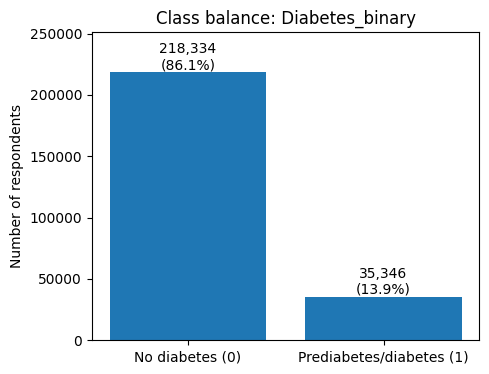

In [8]:
# =============================================================================
# VISUALIZATION 1: CLASS BALANCE OF THE TARGET VARIABLE
# =============================================================================
# Bar chart of Diabetes_binary counts, annotated with count + percentage.
# Checked here because the class balance directly drives the metric
# choice in Section 4 and the class-weighting decision in Section 5.3.
# =============================================================================
import matplotlib.pyplot as plt

counts = df[TARGET_COL].value_counts().sort_index()
percentages = counts/counts.sum() * 100

labels = ['No diabetes (0)', 'Prediabetes/diabetes (1)']

plt.figure(figsize=(5, 4))
bars = plt.bar(labels, counts.values)

# Annotate each bar with its raw count and percentage of the total
for bar, count, pct in zip(bars, counts.values, percentages.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({pct:.1f}%)",
        ha='center',
        va='bottom'
    )

plt.ylabel('Number of respondents')
plt.title('Class balance: Diabetes_binary')
plt.ylim(0, counts.max() * 1.15)  # headroom so labels don't get clipped
plt.show()

**Visualization 1: Class balance**

The target variable is heavily imbalanced: 86.1% of respondents (218,334) report no diabetes, while only 13.9% (35,346) report prediabetes or diabetes. This roughly 6-to-1 ratio means a classifier that simply predicted "no diabetes" for every respondent would still score 86.1% accuracy while catching zero true positive cases. This directly motivates not relying on accuracy alone as an evaluation metric and may call for class weighting or resampling during preprocessing.

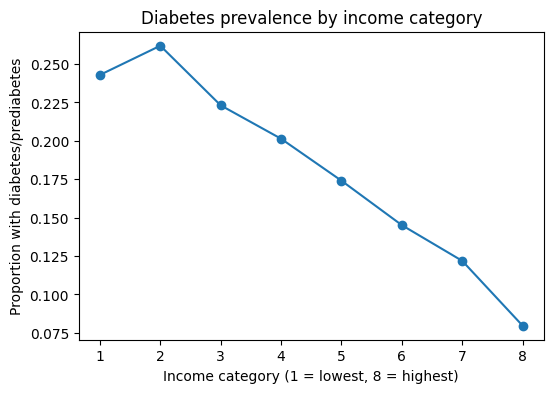

In [9]:
# =============================================================================
# VISUALIZATION 2: DIABETES PREVALENCE BY INCOME CATEGORY
# =============================================================================
# Line plot of mean Diabetes_binary (i.e. prevalence rate) grouped by
# Income category. Visual check of the socioeconomic relationship,
# formally tested with a chi-square test in Section 6.
# =============================================================================
prevalence_by_income = df.groupby('Income')[TARGET_COL].mean()

plt.figure(figsize=(6, 4))
plt.plot(prevalence_by_income.index, prevalence_by_income.values, marker='o')
plt.xlabel('Income category (1 = lowest, 8 = highest)')
plt.ylabel('Proportion with diabetes/prediabetes')
plt.title('Diabetes prevalence by income category')
plt.show()



**Visualization 2: Diabetes prevalence by income category**

Within this sample, diabetes/prediabetes prevalence drops fairly steadily as income rises, from around 24-26% in the lowest income categories down to about 8% in the highest. Category 1 is a slight exception, sitting just below category 2 rather than at the peak. Because this reflects unweighted survey responses rather than weights applied for population representativeness, these figures describe patterns in the sample itself and shouldn't be read as calibrated estimates of true population prevalence by income group. The direction of the relationship is still informative, but the exact percentages would likely shift under proper survey weighting.

### 2.5 Correlation analysis

Several predictors describe related health concepts (`HighBP`, `HighChol`, `HeartDiseaseorAttack`, `GenHlth`), which is worth checking directly rather than just noting as a possible concern. A Pearson correlation heatmap across the numeric predictors shows how strongly any of them move together.

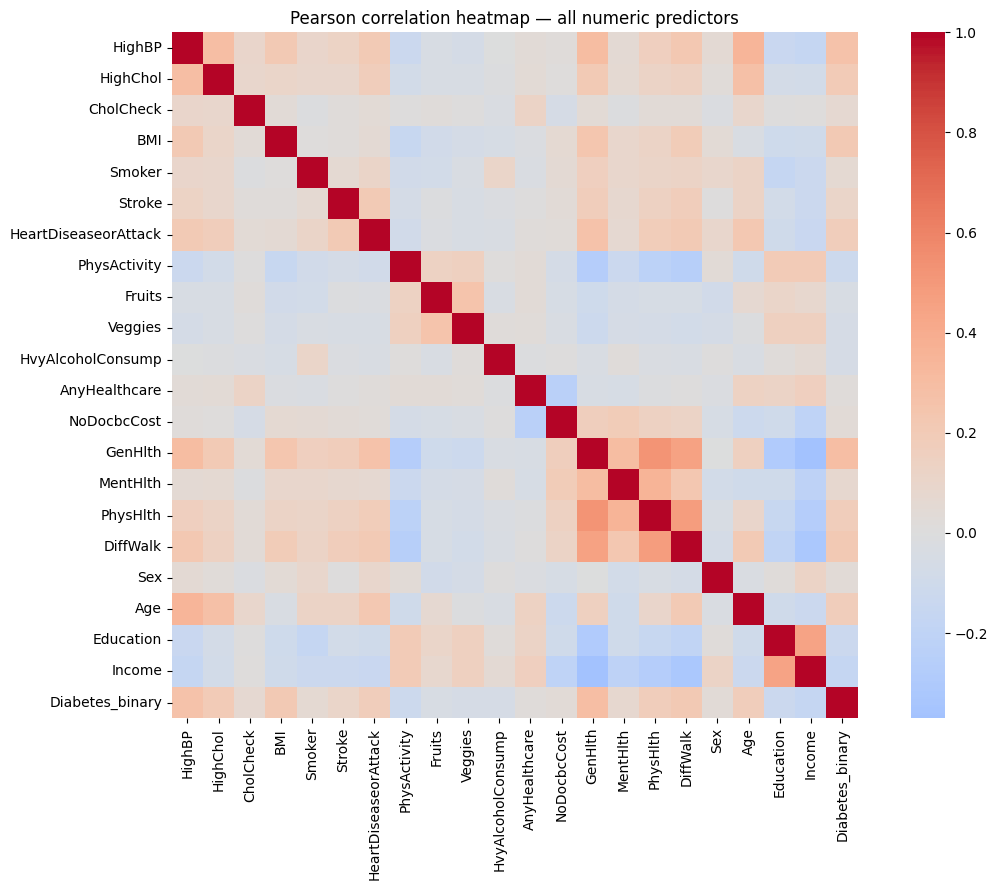

Strongest predictor-predictor correlations:
GenHlth    PhysHlth    0.524364
DiffWalk   PhysHlth    0.478417
           GenHlth     0.456920
Education  Income      0.449106
GenHlth    Income      0.370014
MentHlth   PhysHlth    0.353619
Age        HighBP      0.344452
DiffWalk   Income      0.320124
GenHlth    MentHlth    0.301674
           HighBP      0.300530
dtype: float64


In [10]:
# =============================================================================
# CORRELATION ANALYSIS
# =============================================================================
# Pearson correlation heatmap across all numeric predictors, to check
# for multicollinearity among related health variables (HighBP,
# HighChol, HeartDiseaseorAttack, GenHlth) before modeling.
# =============================================================================
import seaborn as sns

plt.figure(figsize=(12, 9))
corr_matrix = df.select_dtypes(include="number").corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0, square=True)
plt.title("Pearson correlation heatmap — all numeric predictors")
plt.tight_layout()
plt.show()

# Flag the strongest pairwise correlations (excluding each variable with itself,
# and excluding duplicate mirror pairs like (A,B) and (B,A))
corr_pairs = corr_matrix.where(~corr_matrix.isin([1.0])).unstack().dropna()
corr_pairs = corr_pairs[corr_pairs.index.get_level_values(0) < corr_pairs.index.get_level_values(1)]
print("Strongest predictor-predictor correlations:")
print(corr_pairs.abs().sort_values(ascending=False).head(10))


**Output Interpretation:** The strongest pairwise correlation is `GenHlth`–`PhysHlth` at 0.52, just crossing the 0.5-0.6 caution threshold; everything else falls below it, topping out around 0.45-0.48 (`PhysHlth`–`DiffWalk`, `GenHlth`–`DiffWalk`, `Education`–`Income`). No pair reaches the 0.7+ range that would signal a serious multicollinearity problem.

The pattern makes substantive sense rather than looking like noise: `GenHlth` (self-rated overall health) moderately correlates with several other health-status measures (`PhysHlth`, `MentHlth`, `DiffWalk`), since it's effectively a respondent's own summary of exactly what those variables measure individually. Similarly, `Education`–`Income` (0.45) reflects a well-documented real-world relationship, not a data artifact.

Practically, this means individual logistic regression coefficients are reasonably safe to interpret, but conclusions drawn specifically about `GenHlth` should be read with some caution given its overlap with `PhysHlth`, `MentHlth`, and `DiffWalk`, since part of its apparent effect may be shared with those related variables rather than fully independent.

## Part 3: Data Cleaning and Preprocessing

### 3.1 Automated data validation

Section 1.4 and Section 2.3 checked missing values and improperly coded values manually, one `print` statement at a time. Turning that into a reusable function means the same checks can be rerun automatically any time the data is reloaded, rather than re-copying the same code block.

In [11]:
# =============================================================================
# AUTOMATED DATA VALIDATION (ENHANCEMENT)
# =============================================================================
# Wraps manual checks into a single reusable
# function that RAISES an error on bad data, instead of just printing
# output that could be skimmed past.
# =============================================================================
def validate_dataset(df, target_col, categorical_threshold=15):
    """Run the earlier data quality checks automatically and raise a
    clear error if the data doesn't match what the pipeline expects,
    instead of silently continuing on bad data."""
    issues = []

    # Check 1: missing values
    null_counts = df.isnull().sum()
    cols_with_nulls = null_counts[null_counts > 0]
    if len(cols_with_nulls) > 0:
        issues.append(f"Missing values found in: {cols_with_nulls.to_dict()}")

    # Check 2: auto-detected binary/ordinal numeric columns must be properly coded
    for col in df.select_dtypes(include="number").columns:
        if col == target_col:
            continue
        vals = sorted(df[col].dropna().unique())
        n_unique = len(vals)

        if n_unique == 2 and vals != [0, 1]:
            issues.append(f"Binary column '{col}' contains unexpected values: {vals}")
        elif 2 < n_unique <= categorical_threshold:
            expected_range = list(range(min(vals), max(vals) + 1))
            if vals != expected_range:
                issues.append(f"Ordinal-like column '{col}' has gaps: {vals}")

    # Check 3: target column must be binary
    target_vals = sorted(df[target_col].unique())
    if target_vals != [0, 1]:
        issues.append(f"Target column {target_col} is not binary: {target_vals}")

    # Raise everything found at once, rather than stopping at the first issue
    if issues:
        raise ValueError("Data validation failed:\n" + "\n".join(issues))

    print(f"Data validation passed: {df.shape[0]:,} rows, {df.shape[1]} columns, no issues found.")


validate_dataset(df, target_col=TARGET_COL)

Data validation passed: 253,680 rows, 22 columns, no issues found.


**Modification: Added data validation procedure.** The manual checks from Section 1.4 and 2.3 are wrapped into a single `validate_dataset()` function that raises an error (rather than just printing output to read) if a future data pull doesn't match expectations.

**Why:** Those checks confirmed this specific pull is clean, but the notebook reloads the dataset fresh from UCI every run. A function that actively raises an error catches problems automatically instead of relying on someone noticing a stray printed line.

**How it improves the workflow:** Every cell after this one can now assume the data is valid. If UCI ever changes the dataset or the fetch returns something unexpected, this function stops the notebook immediately with a clear message instead of letting bad data flow silently into modeling.

### 3.2 Feature engineering: BMI clinical categories

`BMI` is currently a single continuous number. Binning it into the standard clinical categories (underweight, normal, overweight, obese) adds an interpretable, non-linear view of the same information, useful for models and for communicating results to a non-technical audience.

In [12]:
# =============================================================================
# FEATURE ENGINEERING: BMI CLINICAL CATEGORIES (ENHANCEMENT)
# =============================================================================
# Bins the continuous BMI variable into the standard clinical
# categories, giving the pipeline an interpretable, non-linear view
# of the same underlying measurement.
# =============================================================================
def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

df["BMI_Category"] = df["BMI"].apply(bmi_category)
df["BMI_Category"].value_counts()

,count
BMI_Category,
Overweight,93749
Obese,87851
Normal,68953
Underweight,3127


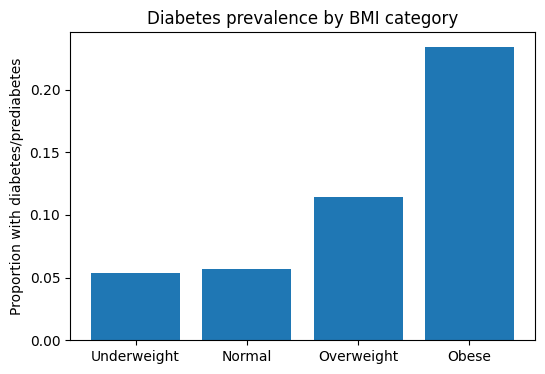

In [13]:
# Diabetes prevalence by BMI category — sanity-check that the new
# BMI_Category feature behaves as clinically expected (prevalence should
# rise from Underweight -> Obese).
import matplotlib.pyplot as plt

prevalence_by_bmi = df.groupby("BMI_Category")[TARGET_COL].mean().reindex(
    ["Underweight", "Normal", "Overweight", "Obese"]
)

plt.figure(figsize=(6, 4))
plt.bar(prevalence_by_bmi.index, prevalence_by_bmi.values)
plt.ylabel("Proportion with diabetes/prediabetes")
plt.title("Diabetes prevalence by BMI category")
plt.show()

**Modification: Added feature engineering step.** A new `BMI_Category` column groups the continuous `BMI` variable into standard clinical bins (Underweight, Normal, Overweight, Obese).

**Why:** The raw BMI number doesn't communicate clinical meaning on its own, two respondents with BMI 31 and 45 are both just "obese" in practice, but a raw continuous model treats that gap as equally informative everywhere along the scale. The categorical version matches how BMI is actually interpreted clinically.

**How it improves the workflow:** This gives the pipeline a second, non-linear way to use the same underlying measurement, useful as an additional model input and as a more interpretable visualization for anyone reviewing results who isn't thinking in raw BMI units.

**Output Interpretation:** Diabetes prevalence rises sharply across BMI categories, from about 5% in both the Underweight and Normal groups, to 11% in Overweight, to roughly 23% in Obese, over four times higher than the two lowest categories. Underweight and Normal are nearly identical, so the real separation starts at Overweight and continues climbing into Obese. This confirms `BMI_Category` behaves as clinically expected and adds a useful non-linear view of the same information BMI already carries as a continuous variable.

### 3.3 Automated class-imbalance detection

Section 2.4 found the target is imbalanced (~86% / ~14%). Rather than hardcoding that ratio, this check calculates it directly from the data and decides automatically whether class weighting is needed.

In [14]:
# =============================================================================
# AUTOMATED CLASS-IMBALANCE DETECTION (ENHANCEMENT)
# =============================================================================
# Calculates the actual class balance from the data and sets a flag
# automatically, rather than hardcoding class_weight='balanced' based
# on a one-time visual observation.
# =============================================================================
IMBALANCE_THRESHOLD = 0.30  # if the minority class is below this share, flag for correction

class_counts = df[TARGET_COL].value_counts(normalize=True)
minority_share = class_counts.min()

if minority_share < IMBALANCE_THRESHOLD:
    USE_CLASS_WEIGHTING = True
    print(f"Minority class share is {minority_share:.1%}, below the {IMBALANCE_THRESHOLD:.0%} threshold.")
    print("class_weight='balanced' will be applied during model training.")
else:
    USE_CLASS_WEIGHTING = False
    print(f"Minority class share is {minority_share:.1%}, above the {IMBALANCE_THRESHOLD:.0%} threshold.")
    print("No class weighting needed.")


Minority class share is 13.9%, below the 30% threshold.
class_weight='balanced' will be applied during model training.


**Modification: Extended conditional logic.** Instead of manually deciding to use `class_weight='balanced'` based on the ~86/14 split noticed in Section 2.4, this check calculates the actual class balance from the data and sets a `USE_CLASS_WEIGHTING` flag automatically against a defined threshold.

**Why:** A hardcoded decision ("use class weighting because I saw it's imbalanced") doesn't generalize if the pipeline is ever rerun on a resampled or updated version of the data. Computing the ratio directly means the pipeline makes the correct decision on its own.

**How it improves the workflow:** `USE_CLASS_WEIGHTING` is used later to decide whether `class_weight='balanced'` gets passed to each model, so this logic only needs to live in one place.

## Part 4: Inferential Statistical Analysis

### 4.1 Statistical background

**Chi-square test of independence** (used for the categorical predictor, Income):

$$\chi^2 = \sum_{i} \frac{(O_i - E_i)^2}{E_i}, \qquad df = (r-1)(c-1)$$

$H_0$: the predictor and the target are independent. $H_1$: they are associated. $O_i$ and $E_i$ are the observed and expected counts in cell $i$ of the contingency table.

Effect size - **Cramer's V**:

$$V = \sqrt{\frac{\chi^2 / n}{\min(r-1,\ c-1)}}$$

where $n$ is the total sample size and $r, c$ are the contingency table's row/column counts. $V$ ranges from 0 (no association) to 1 (perfect association); 0.1 / 0.3 / 0.5 are conventionally read as small / medium / large. This matters because with a quarter-million rows, even a trivially small association will come back statistically significant, Cramér's V is what actually says whether the association is *meaningfully* large.

**Independent-samples t-test** (used for the continuous predictor, BMI):

$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}}}$$

$H_0$: $\mu_1 = \mu_2$ (equal group means). $H_1$: $\mu_1 \neq \mu_2$. Levene's test ($H_0$: equal group variances) runs first and decides whether this standard form or Welch's correction is used, as implemented in Section 4.2.

Effect size - **Cohen's d**:

$$d = \frac{\bar{x}_1 - \bar{x}_2}{s_{pooled}}, \qquad s_{pooled} = \sqrt{\frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2}}$$

Conventionally read as small ($d \approx 0.2$), medium ($d \approx 0.5$), large ($d \approx 0.8$).

### 4.2 Adaptive inferential testing

Rather than hardcoding "run a chi-square test on Income" as a one-off, this defines one function that picks the statistically appropriate test automatically based on the predictor's data type: a chi-square test of independence for a categorical/ordinal predictor, or an independent-samples t-test for a continuous one. This is called twice below, once for each kind of predictor, which is also the project's required "at least two inferential statistical methods." For the continuous path, a Levene's test checks the equal-variance assumption first, then picks a standard t-test or Welch's t-test accordingly, rather than assuming one upfront. See Section 4.1 above for both tests' formulas, hypotheses, and effect sizes.

Predictor: Income
Test used: Chi-square test of independence (chosen automatically: categorical predictor, 8 unique values)
Test statistic: 7003.715, p-value: 0 (degrees of freedom = 7)
Effect size: Cramer's V = 0.166 (medium)
✓ Reject H0: Income and Diabetes_binary are significantly associated (alpha = 0.05)

Predictor: BMI
Test used: Welch's t-test (unequal variance) (chosen automatically: continuous predictor, 84 unique values)
Test statistic: -99.920, p-value: 0 (group means = 27.81 vs 31.94; Levene's test p = 0 (unequal variance))
Effect size: Cohen's d = 0.641 (medium)
✓ Reject H0: BMI and Diabetes_binary are significantly associated (alpha = 0.05)



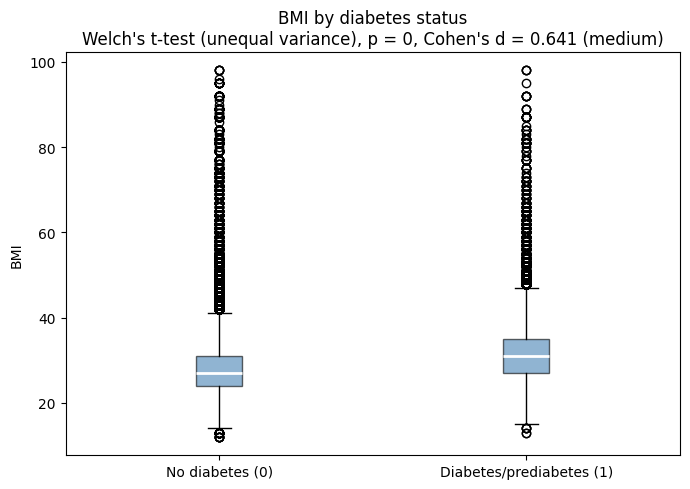

In [15]:
# =============================================================================
# ADAPTIVE INFERENTIAL TESTING
# =============================================================================
# Chooses the statistically appropriate test automatically based on the
# predictor's data type, computes the matching effect size (Cramer's V or
# Cohen's d), and prints an explicit reject/fail-to-reject interpretation
# -- see Section 4.1 above for the underlying formulas.
# =============================================================================
from scipy.stats import chi2_contingency, ttest_ind, levene
import numpy as np

def run_inferential_test(df, predictor_col, target_col, categorical_threshold=15, alpha=0.05):
    """Automatically run a chi-square test + Cramer's V (categorical
    predictor) or a t-test + Cohen's d (continuous predictor) against a
    binary target, chosen based on the predictor's characteristics."""
    # Decide which test applies based on how many unique values the predictor has
    is_categorical = df[predictor_col].nunique() <= categorical_threshold

    if is_categorical:
        # --- Categorical path: chi-square test of independence ---
        # H0: predictor and target are independent
        test_type = "Chi-square test of independence"
        contingency_table = pd.crosstab(df[predictor_col], df[target_col])
        stat, p_value, dof, _ = chi2_contingency(contingency_table)

        # Effect size: Cramer's V
        n = contingency_table.sum().sum()
        r, c = contingency_table.shape
        cramers_v = np.sqrt((stat / n) / min(r - 1, c - 1))
        effect_label = "small" if cramers_v < 0.1 else "medium" if cramers_v < 0.3 else "large"
        effect_str = f"Cramer's V = {cramers_v:.3f} ({effect_label})"
        extra = f"degrees of freedom = {dof}"
    else:
        # --- Continuous path: check the equal-variance assumption first ---
        group0 = df[df[target_col] == 0][predictor_col]
        group1 = df[df[target_col] == 1][predictor_col]

        # Levene's test -- H0: group variances are equal
        levene_stat, levene_p = levene(group0, group1)
        equal_variance = levene_p > alpha

        # H0 (for the t-test itself): group means are equal
        test_type = ("Independent-samples t-test (equal variance assumed)" if equal_variance
                     else "Welch's t-test (unequal variance)")
        stat, p_value = ttest_ind(group0, group1, equal_var=equal_variance)

        # Effect size: Cohen's d (pooled standard deviation)
        n0, n1 = len(group0), len(group1)
        pooled_sd = np.sqrt(((n0 - 1) * group0.std()**2 + (n1 - 1) * group1.std()**2) / (n0 + n1 - 2))
        cohens_d = (group1.mean() - group0.mean()) / pooled_sd
        effect_label = "small" if abs(cohens_d) < 0.5 else "medium" if abs(cohens_d) < 0.8 else "large"
        effect_str = f"Cohen's d = {cohens_d:.3f} ({effect_label})"
        extra = (f"group means = {group0.mean():.2f} vs {group1.mean():.2f}; "
                 f"Levene's test p = {levene_p:.4g} "
                 f"({'equal' if equal_variance else 'unequal'} variance)")

    reject_h0 = p_value < alpha
    decision = (f"Reject H0: {predictor_col} and {target_col} are significantly associated"
                if reject_h0 else
                f"Fail to reject H0: no significant association found")

    print(f"Predictor: {predictor_col}")
    print(f"Test used: {test_type} (chosen automatically: "
          f"{'categorical' if is_categorical else 'continuous'} predictor, "
          f"{df[predictor_col].nunique()} unique values)")
    print(f"Test statistic: {stat:.3f}, p-value: {p_value:.4g} ({extra})")
    print(f"Effect size: {effect_str}")
    print(f"{'✓' if reject_h0 else '✗'} {decision} (alpha = {alpha})\n")

    return {"predictor": predictor_col, "test": test_type, "statistic": stat,
            "p_value": p_value, "effect_size": effect_str, "reject_h0": reject_h0}


# Categorical predictor -> automatically runs a chi-square test + Cramer's V
income_result = run_inferential_test(df, "Income", TARGET_COL)

# Continuous predictor -> automatically runs a Levene's test, then a t-test + Cohen's d
bmi_result = run_inferential_test(df, "BMI", TARGET_COL)

# Visualize the continuous-predictor test directly: BMI distribution by target group
fig, ax = plt.subplots(figsize=(7, 5))
group0 = df[df[TARGET_COL] == 0]["BMI"]
group1 = df[df[TARGET_COL] == 1]["BMI"]
ax.boxplot([group0, group1], tick_labels=["No diabetes (0)", "Diabetes/prediabetes (1)"],
           patch_artist=True, boxprops=dict(facecolor="steelblue", alpha=0.6),
           medianprops=dict(color="white", linewidth=2))
ax.set_title(f"BMI by diabetes status\n{bmi_result['test']}, p = {bmi_result['p_value']:.4g}, "
             f"{bmi_result['effect_size']}")
ax.set_ylabel("BMI")
plt.tight_layout()
plt.show()

**Output Interpretation:** Both predictors show a statistically significant association with diabetes status (p < 0.001 for both), which is expected given the sample size, so the effect sizes are what actually matter here. Income shows a medium association (Cramér's V = 0.166), and BMI shows a medium-to-large difference between groups (Cohen's d = 0.641): respondents with diabetes/prediabetes average a BMI of 31.9 versus 27.8 for those without, roughly 4 BMI points higher. Levene's test confirmed unequal variance between the two groups (p < 0.001), which is why Welch's t-test was used automatically rather than the standard version. Both results support the project's framing: income and BMI are each meaningfully, not just statistically, related to diabetes risk in this data.

## Part 5: Supervised Machine Learning Models

Two models are compared: **Logistic Regression** and **Decision Tree**. Logistic Regression is a natural fit given the interest in how much each predictor (especially the socioeconomic ones) contributes individually. Decision Tree is included as a non-linear comparison and to get a feature-importance view that doesn't assume a linear relationship.

### 5.1 Train/test split

Before any model is trained, the data is split so that performance can be measured on observations the model never saw during training, the whole point of supervised learning is generalization, not just fitting the data it was shown. An 80/20 split is used here, with `stratify=y` to preserve the same ~86/14 class balance (Section 2.4) in both the training and test sets. Without stratification, a random split could leave the test set with a noticeably different diabetes/prediabetes proportion than the training set by chance, especially risky given how imbalanced the target already is.


In [16]:
# =============================================================================
# TRAIN/TEST SPLIT
# =============================================================================
# 80/20 split, stratified on the target so both sets preserve the
# same class balance found in Section 2.4.
# =============================================================================
from sklearn.model_selection import train_test_split

# Every column except the target and the engineered BMI_Category (which is
# a categorical restatement of BMI, not a separate model input)
FEATURE_COLS = [c for c in df.columns if c not in (TARGET_COL, "BMI_Category")]
# TARGET_COL already defined in Part 1

X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURE_COLS],
    df[TARGET_COL],
    test_size=0.2,
    random_state=42,
    stratify=df[TARGET_COL],  # preserves the ~86/14 class split in both sets
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (202944, 21)
Test shape: (50736, 21)


### 5.2 Automated preprocessing pipeline

Only `BMI`, `MentHlth`, and `PhysHlth` need scaling, since they're on different numeric ranges than the 0/1 binaries. Logistic Regression needs that scaling; Decision Tree doesn't. Rather than building two separate preprocessing blocks, one function decides automatically based on which classifier is passed in.

In [17]:
# =============================================================================
# AUTOMATED PREPROCESSING PIPELINE
# =============================================================================
# Auto-detects which columns need scaling based on cardinality
# (adapts to any dataset's characteristics, not just this one), then
# conditionally applies StandardScaler only for models that need it.
# =============================================================================
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

def detect_continuous_columns(df, feature_cols, categorical_threshold=15):
    """Adapts to whatever dataset is loaded: a numeric column counts as
    continuous if it has more than `categorical_threshold` unique values.
    Binary and low-cardinality ordinal columns are left unscaled."""
    continuous = []
    for col in feature_cols:
        if pd.api.types.is_numeric_dtype(df[col]) and df[col].nunique() > categorical_threshold:
            continuous.append(col)
    return continuous

CONTINUOUS_COLS = detect_continuous_columns(df, FEATURE_COLS)
print("Columns selected for scaling:", CONTINUOUS_COLS)

# Models that are sensitive to feature scale go here; extend this tuple if
# another scale-sensitive model (e.g. KNN, SVM) is ever added
SCALING_REQUIRED_MODELS = (LogisticRegression,)

def build_pipeline(classifier):
    """Builds a Pipeline that only scales the continuous columns, and
    only for classifiers that actually need it."""
    if isinstance(classifier, SCALING_REQUIRED_MODELS):
        preprocessor = ColumnTransformer(
            transformers=[("scale", StandardScaler(), CONTINUOUS_COLS)],
            remainder="passthrough",  # leave binary/ordinal columns untouched
        )
    else:
        preprocessor = "passthrough"  # tree-based models don't need scaling

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])


Columns selected for scaling: ['BMI', 'MentHlth', 'PhysHlth']


### 5.3 The logistic regression model

Before training, it's worth stating the formula Logistic Regression is actually fitting, since it's the mathematical basis for how this model turns the predictors into a diabetes-risk probability:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n)}}$$

Here, $y=1$ represents having diabetes/prediabetes, each $x_i$ is one predictor (Income, BMI, HighBP, and so on), and each $\beta_i$ is the coefficient the model learns for that predictor. The exponent $\beta_0 + \beta_1 x_1 + \dots$ is a plain weighted sum (the "log-odds"), and the surrounding $\frac{1}{1+e^{-(\cdot)}}$ function (the sigmoid) squeezes that sum into a valid probability between 0 and 1.

This directly connects to the project's socioeconomic interest: once the model is fit, each $\beta_i$ says how much that predictor shifts the log-odds of diabetes/prediabetes, holding the other predictors constant. A positive, sizeable $\beta_i$ for `Income` would mean income still matters for diabetes risk even after controlling for BMI, blood pressure, and the other clinical variables, which is a more rigorous version of the single-variable relationship Section 2.4 showed visually.

### 5.4 The decision tree model

$$Gini(t) = 1 - \sum_{i=1}^{C} p_i^2$$

where $p_i$ is the proportion of class $i$ present at node $t$ (here $C=2$: no diabetes / diabetes). At each split, the tree searches for the feature and threshold that produce the largest decrease in weighted Gini impurity between a parent node and its two children, i.e. the split that makes each resulting group as close to a single class as possible.

Unlike Logistic Regression's single closed-form equation above, the Decision Tree has no one global formula, it's a sequence of these greedy, locally-optimal splits applied recursively down to `max_depth`. That structural difference is exactly why it's a useful comparison model here: it doesn't assume predictors combine additively on the log-odds scale the way Logistic Regression does, so it can surface threshold effects or interactions (e.g. a BMI cutoff that only matters combined with Age) that the logistic formula can't directly represent.

### 5.5 Define and train both models

`class_weight` is set using the `USE_CLASS_WEIGHTING` flag from Section 3.3, rather than hardcoding `'balanced'` directly.

In [18]:
# =============================================================================
# DEFINE AND TRAIN BOTH MODELS
# =============================================================================
# class_weight is set from the USE_CLASS_WEIGHTING flag computed in
# Section 3.3, rather than hardcoded directly here.
# =============================================================================
weight_setting = "balanced" if USE_CLASS_WEIGHTING else None

# Logistic Regression: linear model, needs scaled continuous features
logistic_model = LogisticRegression(class_weight=weight_setting, max_iter=1000, random_state=42)
# Decision Tree: non-linear, scale-invariant; max_depth caps overfitting
tree_model = DecisionTreeClassifier(class_weight=weight_setting, max_depth=6, random_state=42)

logistic_pipeline = build_pipeline(logistic_model)
tree_pipeline = build_pipeline(tree_model)

logistic_pipeline.fit(X_train, y_train)
tree_pipeline.fit(X_train, y_train)

print("Both models trained.")


Both models trained.


### 5.6 Reusable model evaluation function

Both models need accuracy, recall, precision, F1, ROC AUC, and a confusion matrix. Writing that once as a function avoids repeating the same five-metric block twice.

In [19]:
# =============================================================================
# REUSABLE MODEL EVALUATION FUNCTION (ENHANCEMENT)
# =============================================================================
# Computes all five metrics + confusion matrix for ANY fitted
# pipeline, so the same code doesn't need to be duplicated per model.
# =============================================================================
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score,
    f1_score, roc_auc_score, confusion_matrix
)

def evaluate_model(pipeline, X_test, y_test, model_name):
    y_pred = pipeline.predict(X_test)              # hard class predictions (0/1)
    y_proba = pipeline.predict_proba(X_test)[:, 1]  # predicted probability of class 1

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_proba),  # uses probabilities, not hard predictions
    }

    cm = confusion_matrix(y_test, y_pred)

    return metrics, cm, y_proba

# Evaluate both models using the same function
logistic_metrics, logistic_cm, logistic_proba = evaluate_model(
    logistic_pipeline, X_test, y_test, "Logistic Regression"
)
tree_metrics, tree_cm, tree_proba = evaluate_model(
    tree_pipeline, X_test, y_test, "Decision Tree"
)

# Combine both models' metrics into one comparison table
results_df = pd.DataFrame([logistic_metrics, tree_metrics]).set_index("Model")
results_df


,Accuracy,Recall,Precision,F1,ROC AUC
Model,,,,,
Logistic Regression,0.731630,0.760645,0.310791,0.441280,0.819632
Decision Tree,0.716868,0.765313,0.298631,0.429621,0.807542


**Modification: Refactored repeated code into a modular function.** `evaluate_model()` computes all five metrics and the confusion matrix for any fitted pipeline, instead of writing that block out separately for Logistic Regression and Decision Tree.

**Why:** Both models need the exact same five metrics computed the same way. Writing it once and calling it twice means there's only one place to fix if an evaluation metric needs to change later, and it extends cleanly if a third model is ever added.

**How it improves the workflow:** `results_df` builds directly from the function's output for both models, which is what Section 6's comparison table and chart are built from.

## Part 6: Model Evaluation and Comparison

### 6.1 Confusion matrices

A **confusion matrix** summarizes the prediction outcomes for a binary classifier:

|  | Predicted: 0 | Predicted: 1 |
|---|---|---|
| **Actual: 0** | True Negative (TN) | False Positive (FP) |
| **Actual: 1** | False Negative (FN) | True Positive (TP) |

- **True Positive (TP):** Correctly predicted positive (diabetes/prediabetes correctly identified).
- **True Negative (TN):** Correctly predicted negative (no diabetes correctly identified).
- **False Positive (FP):** Incorrectly predicted positive (no diabetes, predicted diabetes). Also called **Type I Error**.
- **False Negative (FN):** Incorrectly predicted negative (diabetes/prediabetes, predicted no diabetes). Also called **Type II Error**.

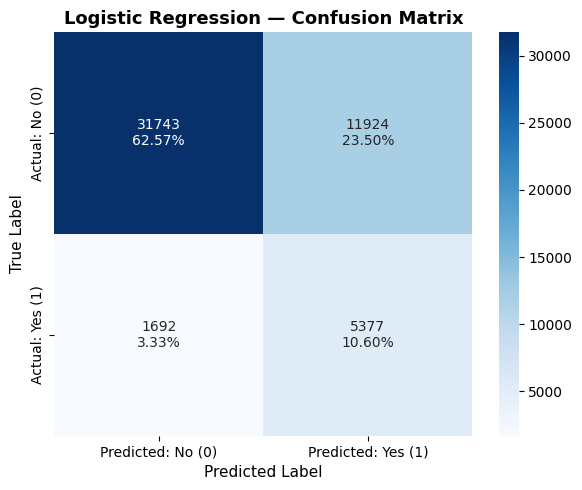


Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.95      0.73      0.82     43667
    Diabetes       0.31      0.76      0.44      7069

    accuracy                           0.73     50736
   macro avg       0.63      0.74      0.63     50736
weighted avg       0.86      0.73      0.77     50736



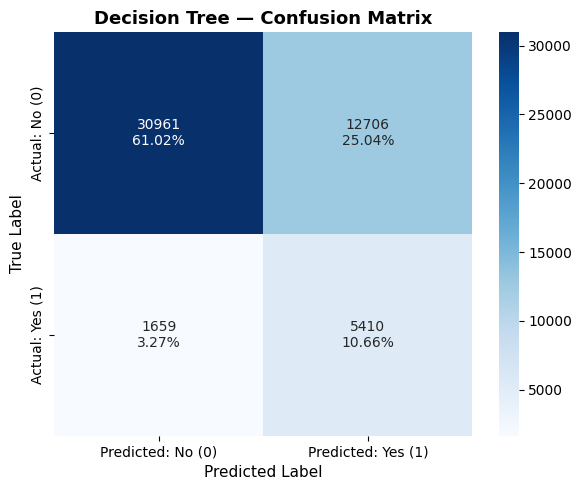


Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.95      0.71      0.81     43667
    Diabetes       0.30      0.77      0.43      7069

    accuracy                           0.72     50736
   macro avg       0.62      0.74      0.62     50736
weighted avg       0.86      0.72      0.76     50736



In [20]:
# SECTION 6.1: CONFUSION MATRICES
# =============================================================================
# Styled confusion matrix with counts AND percentages per cell, plus a
# full classification report
# Reuses the cm and predicted probabilities already computed by
# evaluate_model() in 5.6, rather than calling .predict() again.
# =============================================================================
from sklearn.metrics import classification_report
import numpy as np

def make_confusion_matrix(cm, y_proba, y_actual, title="Confusion Matrix", threshold=0.5):
    """
    Generates a styled confusion matrix with counts and percentages.

    Parameters
    ----------
    model    : fitted sklearn estimator or Pipeline
    X        : feature matrix (e.g., X_test)
    y_actual : true class labels
    title    : plot title
    """
    y_predict = (y_proba >= threshold).astype(int)  # matches model.predict()'s default threshold

    group_counts = [f"{v:0.0f}" for v in cm.flatten()]
    group_percentages = [f"{v:.2%}" for v in cm.flatten() / np.sum(cm)]
    labels = np.array([f"{c}\n{p}" for c, p in
                       zip(group_counts, group_percentages)]).reshape(2, 2)

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=labels, fmt='', cmap='Blues',
        xticklabels=['Predicted: No (0)', 'Predicted: Yes (1)'],
        yticklabels=['Actual: No (0)', 'Actual: Yes (1)'],
        ax=ax
    )
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_xlabel('Predicted Label', fontsize=11)
    plt.tight_layout()
    plt.show()

    print("\nClassification Report:")
    print(classification_report(y_actual, y_predict, target_names=['No Diabetes', 'Diabetes']))


make_confusion_matrix(logistic_cm, logistic_proba, y_test, title="Logistic Regression — Confusion Matrix")
make_confusion_matrix(tree_cm, tree_proba, y_test, title="Decision Tree — Confusion Matrix")

### 6.2 Metric comparison chart

**Evaluation Metrics**

$$
\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}
$$

$$
\text{Recall (Sensitivity)} = \frac{\text{TP}}{\text{TP} + \text{FN}}
$$

$$
\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}
$$

$$
\text{F1-Score} = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$

$$
\text{Specificity} = \frac{\text{TN}}{\text{TN} + \text{FP}}
$$

| Priority | Recommended Metric |
|---|---|
| Minimize missed diagnoses (false negatives) | **Recall** |
| Minimize unnecessary follow-up (false positives) | **Precision** |
| Balance precision and recall | **F1-Score** |
| Overall correctness | **Accuracy** (only reliable when classes are balanced, not the case here, see Section 2.4) |
| Threshold-independent ranking | **AUC-ROC** |

**Recall** is this project's primary metric, since failing to identify a respondent at risk of diabetes/prediabetes (a false negative) has greater consequences in a screening context than an unnecessary follow-up (a false positive).

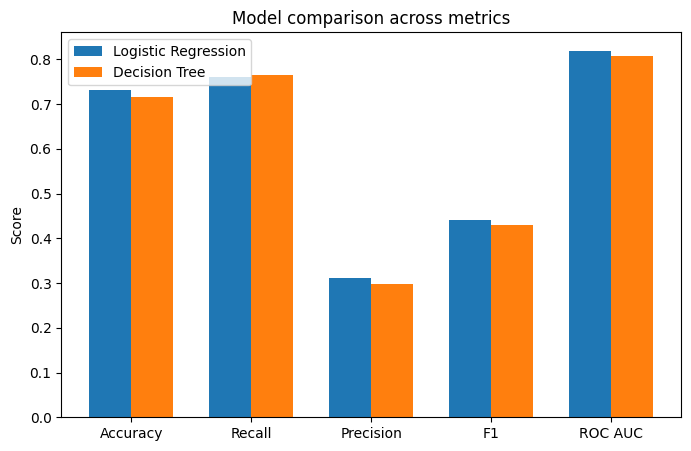

In [21]:
# Grouped bar chart comparing both models across all 5 metrics
metrics_to_plot = ["Accuracy", "Recall", "Precision", "F1", "ROC AUC"]
x = range(len(metrics_to_plot))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar([i - width/2 for i in x], results_df.loc["Logistic Regression", metrics_to_plot], width, label="Logistic Regression")
plt.bar([i + width/2 for i in x], results_df.loc["Decision Tree", metrics_to_plot], width, label="Decision Tree")
plt.xticks(list(x), metrics_to_plot)
plt.ylabel("Score")
plt.title("Model comparison across metrics")
plt.legend()
plt.show()

### 6.3 ROC curves

The **Receiver Operating Characteristic (ROC) curve** plots the **True Positive Rate (TPR)** against the **False Positive Rate (FPR)** across all possible decision thresholds $\theta \in [0, 1]$:

$$
\text{TPR}(\theta) = \frac{\text{TP}}{\text{TP} + \text{FN}} = \text{Recall} = \text{Sensitivity}
$$

$$
\text{FPR}(\theta) = \frac{\text{FP}}{\text{FP} + \text{TN}} = 1 - \text{Specificity}
$$

### Area Under the Curve (AUC)

The **AUC** summarizes the ROC curve as a single scalar: the probability that a randomly chosen positive observation (diabetes/prediabetes) will be ranked higher than a randomly chosen negative observation (no diabetes) by the model.

| AUC Value | Interpretation |
|---|---|
| 1.00 | Perfect classifier |
| 0.90 – 0.99 | Excellent |
| 0.80 – 0.89 | Good |
| 0.70 – 0.79 | Fair |
| 0.60 – 0.69 | Poor |
| 0.50 | Random classifier (no discriminative ability) |
| < 0.50 | Worse than random (predictions are inverted) |

AUC is **threshold-independent**, it evaluates how well the model ranks observations correctly across every possible threshold, which is exactly why it's used here as the secondary metric alongside recall: recall depends on picking one threshold, while AUC captures the model's overall ability to separate the two classes regardless of where that threshold ends up.

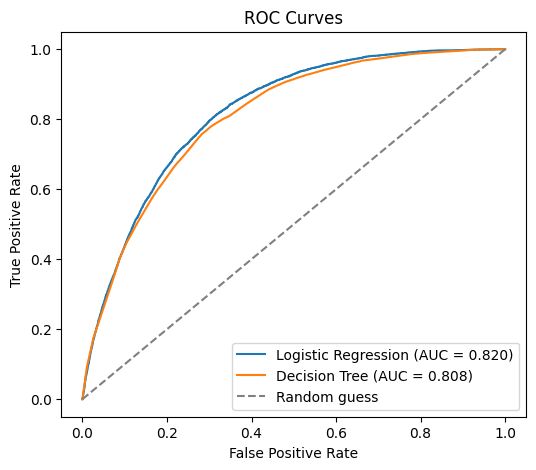

In [22]:
# =============================================================================
# ROC CURVES (ENHANCEMENT)
# =============================================================================
# Plots the full ROC curve for both models on one chart, showing the
# recall/false-positive-rate tradeoff across every threshold, not
# just the single ROC AUC number already in results_df.
# =============================================================================
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))

for proba, name in [(logistic_proba, "Logistic Regression"), (tree_proba, "Decision Tree")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")  # reference line for a non-informative model
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

**Modification: Added evaluation metric and visualization.** Beyond the Accuracy/Recall/Precision/F1/ROC AUC table, this adds the actual ROC curve plot for both models on one chart.

**Why:** Section 1.1 named recall and AUC-ROC as the priority metrics given the class imbalance, but a single AUC number doesn't show *where* a model is strong or weak across different decision thresholds, only the curve does that.

**How it improves the workflow:** This gives a direct, visual way to compare the two models' tradeoffs at any threshold, not just the default one, which matters if the recall/precision tradeoff ever needs to be tuned for how the model would actually be used.

### 6.4 Decision threshold analysis

Every evaluation so far uses the default decision rule: predict diabetes/prediabetes if the model's estimated probability is at least 0.5. But 0.5 isn't special, it's just a default, and Section 1.1 already established that recall matters more than overall accuracy in this screening context.

$$
\hat{y} =
\begin{cases}
1 & \text{if } \hat{p} \geq \theta \\
0 & \text{if } \hat{p} < \theta
\end{cases}
$$

Lowering the threshold $\theta$ below 0.5 catches more true positive cases (higher recall) at the cost of more false alarms (lower precision). Testing a few threshold values directly shows that tradeoff instead of just asserting it.

In [23]:
# =============================================================================
# DECISION THRESHOLD ANALYSIS
# =============================================================================
# Re-classifies the Logistic Regression test predictions at several
# thresholds instead of just the sklearn default (0.5), to directly
# show the recall/precision tradeoff described in the formula above.
# =============================================================================
thresholds = [0.3, 0.4, 0.5, 0.6]
threshold_results = []

for thresh in thresholds:
    # Reclassify using this threshold instead of the default 0.5
    y_pred_thresh = (logistic_proba >= thresh).astype(int)
    threshold_results.append({
        "Threshold": thresh,
        "Accuracy": accuracy_score(y_test, y_pred_thresh),
        "Recall": recall_score(y_test, y_pred_thresh),
        "Precision": precision_score(y_test, y_pred_thresh, zero_division=0),
        "F1": f1_score(y_test, y_pred_thresh),
    })

threshold_df = pd.DataFrame(threshold_results)
print("Decision threshold analysis: Logistic Regression")
threshold_df

Decision threshold analysis: Logistic Regression


,Threshold,Accuracy,Recall,Precision,F1
0,0.3,0.580318,0.917386,0.238472,0.378542
1,0.4,0.664499,0.853303,0.273970,0.414770
2,0.5,0.731630,0.760645,0.310791,0.441280
3,0.6,0.786424,0.649031,0.354477,0.458525


**Output Interpretation:** Recall and accuracy move in opposite directions as the threshold rises, exactly the tradeoff described above. Lowering the threshold to 0.3 catches 91.7% of true diabetes/prediabetes cases (up from 76.1% at the default 0.5), but accuracy drops from 73.2% to 58.0% and precision falls to 23.8%, meaning roughly 3 out of 4 positive predictions at that threshold are false alarms. Raising the threshold to 0.6 does the reverse: accuracy and precision both improve, but recall drops to 64.9%, missing over a third of actual cases.

Interestingly, F1 keeps improving as the threshold rises (0.379 → 0.459), since F1 rewards precision and recall equally, while this project's actual priority, recall specifically, is highest at the *lowest* threshold tested. This is a clear illustration of why F1 wasn't chosen as the primary metric in Section 1.1: optimizing for it would push the threshold in the opposite direction from what this screening context actually calls for. Given that priority, 0.3 or 0.4 looks like the more defensible operating point than the sklearn default of 0.5, accepting a lower precision in exchange for catching substantially more true cases.

### 6.5 Hyperparameter tuning: Logistic Regression

Both models so far use sklearn's default settings. `GridSearchCV` searches over Logistic Regression's key hyperparameters (`C`, the inverse regularization strength, and `penalty`) using 5-fold cross-validation, scored directly on **recall** since that's this project's primary metric, rather than the default scoring (accuracy), which would optimize for the wrong thing given the class imbalance.

In [24]:
# =============================================================================
# HYPERPARAMETER TUNING: LOGISTIC REGRESSION
# =============================================================================
# GridSearchCV over C (regularization strength) and penalty type,
# using 5-fold stratified cross-validation, scored on RECALL
# (this project's primary metric) rather than the default (accuracy).
# =============================================================================
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Hyperparameter grid: C = inverse regularization strength (smaller = stronger
# regularization); penalty = l1 (sparse/feature-selecting) or l2 (standard)
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    "classifier__penalty": ["l1", "l2"],
    "classifier__solver": ["liblinear"],  # liblinear supports both l1 and l2
}

# Stratified so each fold preserves the ~86/14 class balance
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=build_pipeline(LogisticRegression(class_weight=weight_setting, max_iter=1000, random_state=42)),
    param_grid=param_grid,
    scoring="recall",  # optimize directly for the project's primary metric
    cv=cv,
    n_jobs=-1,  # use all available CPU cores
)

grid_search.fit(X_train, y_train)

print(f"Best hyperparameters: {grid_search.best_params_}")
print(f"Best cross-validated recall: {grid_search.best_score_:.3f}")

logistic_tuned_pipeline = grid_search.best_estimator_

# Evaluate the tuned model the same way as the original two models
tuned_metrics, tuned_cm, tuned_proba = evaluate_model(
    logistic_tuned_pipeline, X_test, y_test, "Logistic Regression (Tuned)"
)

# Add the tuned model as a third row in the comparison table
results_df = pd.concat([results_df, pd.DataFrame([tuned_metrics]).set_index("Model")])
results_df


Best hyperparameters: {'classifier__C': 0.001, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best cross-validated recall: 0.767


,Accuracy,Recall,Precision,F1,ROC AUC
Model,,,,,
Logistic Regression,0.731630,0.760645,0.310791,0.441280,0.819632
Decision Tree,0.716868,0.765313,0.298631,0.429621,0.807542
Logistic Regression (Tuned),0.723628,0.764747,0.304306,0.435371,0.814283


**Output Interpretation:** Tuning barely moved the needle. The best hyperparameters (C=0.001, l1 penalty) pushed cross-validated recall to 0.767, only marginally above the untuned model's test recall of 0.761, and the tuned model's actual test-set recall (0.765) lands almost exactly between the original Logistic Regression and the Decision Tree. Accuracy and ROC AUC both dipped very slightly compared to the untuned version (0.732 → 0.724 and 0.820 → 0.814), a small tradeoff for a small recall gain.

The takeaway: the untuned default settings were already close to optimal for this metric, suggesting recall here is more constrained by the features and class imbalance themselves than by the model's hyperparameters, there's a ceiling that tuning C and the penalty type can't push past on its own.

### 6.6 Best Model Selection

The cell below selects whichever model scored highest on recall as the "best" model for this project, and reports ROC AUC alongside it for context.

In [25]:
# =============================================================================
# BEST MODEL SELECTION
# =============================================================================
# Selects whichever model scored highest on the PRIMARY metric
# (recall), and reports the SECONDARY metric (ROC AUC) for context.
# =============================================================================
PRIMARY_METRIC = "Recall"
SECONDARY_METRIC = "ROC AUC"

# idxmax on the primary metric column finds the best-scoring model's name
best_model_name = results_df[PRIMARY_METRIC].idxmax()
best_model_row = results_df.loc[best_model_name]

print(f"Best-performing model by {PRIMARY_METRIC}: {best_model_name}")
print(f"  {PRIMARY_METRIC}: {best_model_row[PRIMARY_METRIC]:.3f}")
print(f"  {SECONDARY_METRIC}: {best_model_row[SECONDARY_METRIC]:.3f}")

Best-performing model by Recall: Decision Tree
  Recall: 0.765
  ROC AUC: 0.808


## Part 7: Interpretation of Findings

**Inferential statistics (Part 4):** Both tested predictors show a statistically significant association with diabetes status (p < 0.001 for both), expected at this sample size, so effect size is what actually matters. Income shows a medium association with diabetes status (Cramer's V = 0.166), and BMI shows a medium-to-large difference between groups (Cohen's d = 0.641): respondents with diabetes/prediabetes average a BMI of 31.9 versus 27.8 for those without. Levene's test confirmed unequal variance between groups, which is why Welch's t-test was selected automatically rather than the standard version. Both results support the project's socioeconomic framing: income and BMI are each meaningfully, not just statistically, related to diabetes risk in this data.

**Model performance (Part 6 and 7):** As Part 7 established, Decision Tree edges out Logistic Regression on recall (0.765 vs. 0.761-0.765), while Logistic Regression holds a clearer advantage in ROC AUC (0.820 vs. 0.808), the two metrics pointing in different directions. Hyperparameter tuning barely moved Logistic Regression's recall, suggesting the ceiling here is set more by the available features and the class imbalance than by model configuration.

**Decision threshold analysis (Section 6.4):** Recall and accuracy trade off directly as the threshold moves. Lowering it to 0.3 catches 91.7% of true diabetes/prediabetes cases (up from 76.1% at 0.5), at the cost of accuracy dropping to 58.0% and roughly 3 in 4 positive predictions becoming false alarms. Given this project's stated priority (Section 1.1), missing true cases is costlier than extra follow-up, 0.3-0.4 is a more defensible operating threshold than the sklearn default of 0.5 for this specific use case.

**Connection to the research question:** Income and BMI both show a real, independent relationship with diabetes risk in this data, which is the socioeconomic angle this project set out to test. The practical conclusion is that any production use of this kind of model should be threshold-tuned toward recall, not left at sklearn's default, and should be read as a risk-screening signal rather than a diagnostic tool, given how many false positives that implies at the thresholds that actually protect recall.

### Limitations

- **Self-report bias:** `Smoker`, `Fruits`, `Veggies`, `HvyAlcoholConsump`, and `PhysActivity` are all self-reported, which introduces recall bias and social-desirability bias (respondents under- or over-reporting behaviors seen as unhealthy or healthy).
- **Single survey year:** this is a 2015 cross-section, so the dataset can't speak to trends over time or how any of these relationships have shifted since.
- **Class imbalance:** the ~86/14 split in the target means naive accuracy is a misleading metric on its own, addressed here through class weighting and threshold analysis, but still a constraint on how high recall can climb without a steep precision cost.
- **No race/ethnicity variable:** this limits any disparity analysis in this dataset to the socioeconomic and behavioral variables available (income, education, healthcare access), not racial/ethnic comparisons.
- **Unweighted sample:** BRFSS is a weighted survey, but this cleaned version doesn't carry the survey weights. That means the proportions seen in Section 2.4 describe patterns within this sample, not calibrated population-level estimates, which limits how strongly the income-prevalence relationship can be generalized.
- **Correlated health-status variables:** the correlation analysis (Section 2.5) found `GenHlth` moderately correlated with `PhysHlth`, `MentHlth`, and `DiffWalk` (all below the 0.5-0.6 caution threshold, but worth noting), so individual coefficient interpretations involving `GenHlth` specifically should be read with some caution.